# Tugas Pertemuan 13 — ANN dan Evaluasi Classifier

Notebook ini mengerjakan Tugas 1–4 yang terdapat pada halaman praktikum dan tugas akhir MNIST.

Sumber: [Modul JS13](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier), [Praktikum 1](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier/praktikum-1), [Praktikum 2](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier/praktikum-2), [Praktikum 3](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier/praktikum-3), dan [Tugas Praktikum](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier/tugas-praktikum).

Jalankan sel berurutan menggunakan **Run All**. MNIST diunduh dari Keras pada penggunaan pertama sehingga memerlukan internet. Seluruh tabel dan interpretasi numerik dihitung dari eksekusi, bukan hasil yang diisi manual. 

## Persiapan
Jika dependensi belum tersedia, jalankan sel instalasi berikut setelah menghapus tanda `#`, kemudian restart kernel. Gunakan kernel Python yang mendukung TensorFlow.

In [1]:
# %pip install tensorflow numpy pandas matplotlib scikit-learn

In [2]:
import os
from pathlib import Path
project_root = Path.cwd().resolve()
if project_root.name == 'Pertemuan 13':
    project_root = project_root.parent
os.environ.setdefault('KERAS_HOME', str(project_root / '.cache' / 'js13' / 'keras'))
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc, cohen_kappa_score)
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0


GPU: []


## Tugas 1 — Backpropagation manual pada XOR
Bandingkan konfigurasi awal 2 neuron sigmoid, 3 neuron sigmoid, serta 2 dan 3 neuron ReLU. Output tetap sigmoid untuk klasifikasi biner. Semua konfigurasi menggunakan seed, learning rate 0,1, dan 10.000 epoch yang sama. Gradien mengikuti pembaruan berbasis jumlah error pada contoh modul; MSE dilaporkan sebagai evaluasi.

Untuk hidden layer: sigmoid memiliki turunan $a(1-a)$, sedangkan ReLU memiliki turunan 1 saat $z>0$ dan 0 selainnya. Bobot kedua layer dihitung gradiennya sebelum diperbarui.

2 neuron / sigmoid | prediksi: [0 0 1 1] | probabilitas: [0.053  0.4955 0.9509 0.5032]


3 neuron / sigmoid | prediksi: [0 1 1 0] | probabilitas: [0.0252 0.9526 0.9512 0.0627]


2 neuron / relu | prediksi: [1 1 1 0] | probabilitas: [0.5001 0.9895 0.5001 0.0088]


3 neuron / relu | prediksi: [0 1 1 0] | probabilitas: [0.0297 0.9861 0.9861 0.0117]


,konfigurasi,MSE akhir,akurasi,detik
0,2 neuron / sigmoid,0.128226,0.50,1.216043
1,3 neuron / sigmoid,0.002297,1.00,1.032768
2,2 neuron / relu,0.125047,0.75,0.930465
3,3 neuron / relu,0.000351,1.00,0.839643


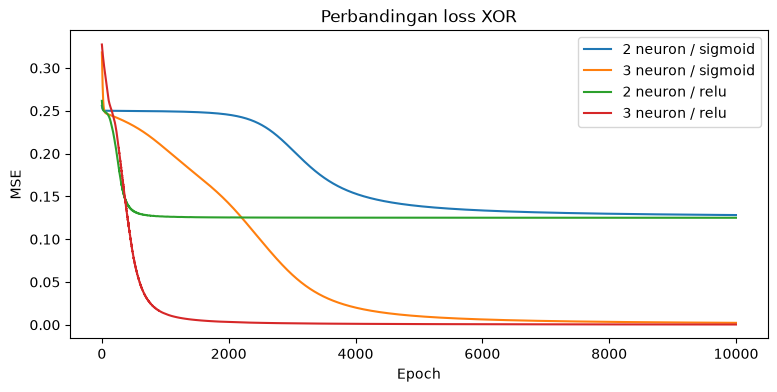

MSE terendah pada percobaan ini: 3 neuron / relu (0.000351).


In [3]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def train_xor(hidden_size, activation, epochs=10000, lr=0.1):
    rng = np.random.RandomState(SEED)
    W1 = rng.randn(2, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = rng.randn(hidden_size, 1)
    b2 = np.zeros((1, 1))
    losses = []
    start = time.perf_counter()
    for _ in range(epochs):
        z1 = X_xor @ W1 + b1
        a1 = sigmoid(z1) if activation == 'sigmoid' else np.maximum(0, z1)
        a2 = sigmoid(a1 @ W2 + b2)
        error = y_xor - a2
        losses.append(float(np.mean(error ** 2)))
        delta2 = error * a2 * (1 - a2)
        derivative = a1 * (1 - a1) if activation == 'sigmoid' else (z1 > 0)
        delta1 = (delta2 @ W2.T) * derivative
        W2 += lr * (a1.T @ delta2)
        b2 += lr * delta2.sum(axis=0, keepdims=True)
        W1 += lr * (X_xor.T @ delta1)
        b1 += lr * delta1.sum(axis=0, keepdims=True)
    z1 = X_xor @ W1 + b1
    a1 = sigmoid(z1) if activation == 'sigmoid' else np.maximum(0, z1)
    probability = sigmoid(a1 @ W2 + b2)
    return probability, losses, time.perf_counter() - start

xor_rows = []
fig, ax = plt.subplots(figsize=(9, 4))
for neurons, activation in [(2, 'sigmoid'), (3, 'sigmoid'), (2, 'relu'), (3, 'relu')]:
    probability, losses, duration = train_xor(neurons, activation)
    prediction = (probability.ravel() >= 0.5).astype(int)
    name = f'{neurons} neuron / {activation}'
    xor_rows.append({'konfigurasi': name, 'MSE akhir': np.mean((y_xor - probability)**2),
                     'akurasi': accuracy_score(y_xor.ravel(), prediction), 'detik': duration})
    print(name, '| prediksi:', prediction, '| probabilitas:', probability.ravel().round(4))
    ax.plot(losses, label=name)
xor_results = pd.DataFrame(xor_rows)
display(xor_results)
ax.set(xlabel='Epoch', ylabel='MSE', title='Perbandingan loss XOR')
ax.legend()
plt.show()
best_xor = xor_results.loc[xor_results['MSE akhir'].idxmin()]
print(f"MSE terendah pada percobaan ini: {best_xor['konfigurasi']} ({best_xor['MSE akhir']:.6f}).")

**Pembahasan:** hidden layer memungkinkan pemisahan nonlinier XOR. Menambah neuron mengubah kapasitas jaringan, tetapi hasil juga dipengaruhi inisialisasi. ReLU dapat menghasilkan neuron tidak aktif jika inputnya selalu negatif. Karena ini satu seed dan hanya empat sampel, peringkat hasil bukan bukti bahwa satu aktivasi selalu lebih unggul.

## Tugas 2 dan 3 — Klasifikasi Iris
Konfigurasi awal mengikuti modul: hidden layer 10 dan 8 neuron, Adam, 50 epoch, batch size 8, dan output softmax 3 kelas. Bandingkan dengan 20 dan 16 neuron, masing-masing menggunakan ReLU dan sigmoid.

Data dibagi secara stratified 80% latih dan 20% uji. Sebagian data latih disisihkan untuk validasi. StandardScaler hanya dipelajari dari subset latih untuk mencegah kebocoran data. Label diubah dengan `to_categorical`, setara one-hot encoding pada modul.

,konfigurasi,loss latih,loss validasi,loss uji,akurasi uji,detik
0,"(10, 8) / relu",0.175656,0.255756,0.246608,0.866667,23.079166
1,"(10, 8) / sigmoid",0.595412,0.589158,0.596674,0.800000,20.969931
2,"(20, 16) / relu",0.107731,0.207417,0.191911,0.900000,20.810941
3,"(20, 16) / sigmoid",0.424170,0.406314,0.436842,0.866667,20.399002


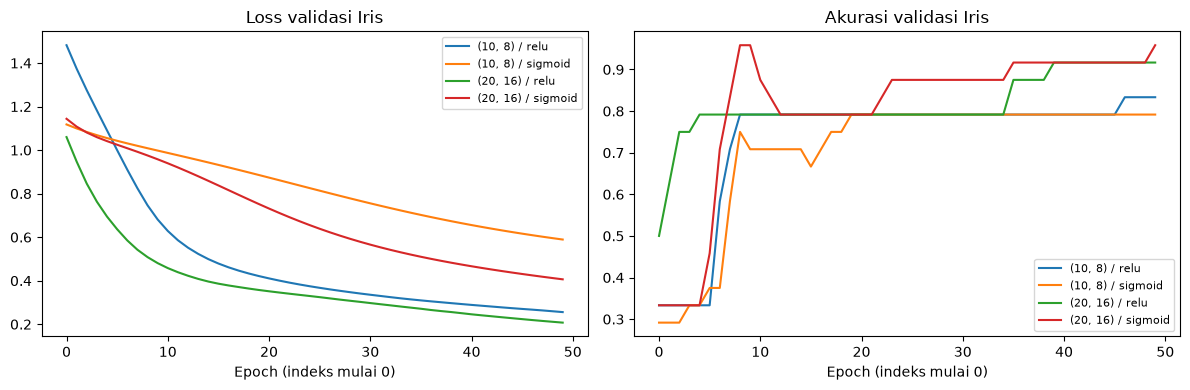

relu: perubahan akurasi setelah penambahan neuron = +0.0333; perubahan loss uji = -0.0547.
sigmoid: perubahan akurasi setelah penambahan neuron = +0.0667; perubahan loss uji = -0.1598.


In [4]:
iris = load_iris()
Xi_train_full, Xi_test, yi_train_full, yi_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=SEED, stratify=iris.target)
Xi_train, Xi_val, yi_train, yi_val = train_test_split(
    Xi_train_full, yi_train_full, test_size=0.2, random_state=SEED, stratify=yi_train_full)
iris_scaler = StandardScaler().fit(Xi_train)
Xi_train, Xi_val, Xi_test = [iris_scaler.transform(x) for x in (Xi_train, Xi_val, Xi_test)]
yi_train_oh, yi_val_oh, yi_test_oh = [to_categorical(y, 3) for y in (yi_train, yi_val, yi_test)]

def build_classifier(shape, hidden, activation, classes, flatten=False):
    model = Sequential([Input(shape=shape)])
    if flatten:
        model.add(Flatten())
    for neurons in hidden:
        model.add(Dense(neurons, activation=activation))
    model.add(Dense(classes, activation='softmax'))
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

iris_rows = []
iris_histories = {}
for hidden in [(10, 8), (20, 16)]:
    for activation in ['relu', 'sigmoid']:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = build_classifier((4,), hidden, activation, 3)
        start = time.perf_counter()
        history = model.fit(Xi_train, yi_train_oh, validation_data=(Xi_val, yi_val_oh),
                            epochs=50, batch_size=8, verbose=0)
        duration = time.perf_counter() - start
        loss, accuracy = model.evaluate(Xi_test, yi_test_oh, verbose=0)
        name = f'{hidden} / {activation}'
        iris_histories[name] = history.history
        iris_rows.append({'konfigurasi': name, 'loss latih': history.history['loss'][-1],
                         'loss validasi': history.history['val_loss'][-1],
                         'loss uji': loss, 'akurasi uji': accuracy, 'detik': duration})
iris_results = pd.DataFrame(iris_rows)
display(iris_results)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in iris_histories.items():
    axes[0].plot(history['val_loss'], label=name)
    axes[1].plot(history['val_accuracy'], label=name)
for ax, title in zip(axes, ['Loss validasi Iris', 'Akurasi validasi Iris']):
    ax.set(xlabel='Epoch (indeks mulai 0)', title=title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for activation in ['relu', 'sigmoid']:
    subset = iris_results[iris_results['konfigurasi'].str.endswith(activation)]
    baseline, modified = subset.iloc[0], subset.iloc[1]
    print(f"{activation}: perubahan akurasi setelah penambahan neuron = "
          f"{modified['akurasi uji'] - baseline['akurasi uji']:+.4f}; "
          f"perubahan loss uji = {modified['loss uji'] - baseline['loss uji']:+.4f}.")

**Pembahasan:** bandingkan aktivasi pada jumlah neuron yang sama agar pengaruh aktivasi dapat diamati. Sigmoid dapat memiliki gradien kecil pada daerah jenuh; ReLU menghindari kejenuhan pada input positif. Penambahan kapasitas tidak menjamin akurasi lebih tinggi. Data uji Iris hanya 30 sampel sehingga satu prediksi mengubah akurasi sekitar 3,33 poin persentase.

## Tugas 4 — Pengaruh learning rate pada regresi harga rumah
Gunakan data dummy luas dan harga dari modul, model 10 neuron ReLU dan satu output linear. Bandingkan learning rate 0,0001; 0,001; 0,01; dan 0,1 dengan Adam selama 100 epoch. Scaler fitur dan target dipisahkan dan hanya dipelajari dari data latih. Prediksi dikembalikan ke skala harga asli.

Tugas perubahan learning rate berada pada contoh data dummy. Contoh Boston setelahnya tidak menjadi dasar eksperimen ini; `load_boston` pada contoh lama juga tidak tersedia pada scikit-learn modern.

,luas,harga
0,50,500
1,60,600
2,70,700
3,80,800
4,90,900


,learning rate,MSE latih standar,MSE uji standar,RMSE harga asli,harga aktual,prediksi harga
0,0.0001,1.124413,1.302540,168.798889,600.0,768.798889
1,0.0010,0.710428,0.741159,127.329712,600.0,727.329712
2,0.0100,0.002722,0.011052,15.548706,600.0,584.451294
3,0.1000,0.000006,0.009332,14.287598,600.0,585.712402


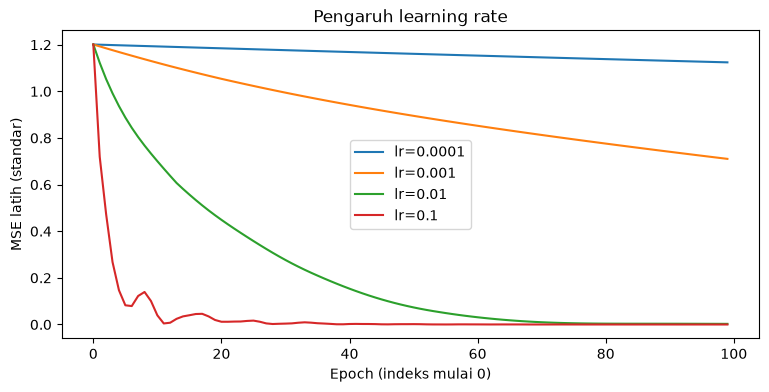

Loss latih akhir terendah: lr=0.1, MSE=0.000006.


In [5]:
houses = pd.DataFrame({'luas': [50, 60, 70, 80, 90], 'harga': [500, 600, 700, 800, 900]})
display(houses)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    houses[['luas']].to_numpy(), houses[['harga']].to_numpy(), test_size=0.2, random_state=SEED)
sx, sy = StandardScaler().fit(Xr_train), StandardScaler().fit(yr_train)
Xr_train_s, Xr_test_s = sx.transform(Xr_train), sx.transform(Xr_test)
yr_train_s, yr_test_s = sy.transform(yr_train), sy.transform(yr_test)
reg_rows = []
fig, ax = plt.subplots(figsize=(9, 4))
for lr in [0.0001, 0.001, 0.01, 0.1]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = Sequential([Input(shape=(1,)), Dense(10, activation='relu'), Dense(1)])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    history = model.fit(Xr_train_s, yr_train_s, epochs=100, batch_size=4, verbose=0)
    test_loss = model.evaluate(Xr_test_s, yr_test_s, verbose=0)
    pred = sy.inverse_transform(model.predict(Xr_test_s, verbose=0))
    reg_rows.append({'learning rate': lr, 'MSE latih standar': history.history['loss'][-1],
                     'MSE uji standar': test_loss, 'RMSE harga asli': np.sqrt(np.mean((yr_test-pred)**2)),
                     'harga aktual': float(yr_test[0, 0]), 'prediksi harga': float(pred[0, 0])})
    ax.plot(history.history['loss'], label=f'lr={lr}')
reg_results = pd.DataFrame(reg_rows)
display(reg_results)
ax.set(xlabel='Epoch (indeks mulai 0)', ylabel='MSE latih (standar)', title='Pengaruh learning rate')
ax.legend()
plt.show()
best_reg = reg_results.loc[reg_results['MSE latih standar'].idxmin()]
print(f"Loss latih akhir terendah: lr={best_reg['learning rate']}, "
      f"MSE={best_reg['MSE latih standar']:.6f}.")

**Pembahasan:** learning rate kecil dapat membuat konvergensi lambat dalam 100 epoch, sedangkan nilai besar dapat menyebabkan osilasi. Gunakan kurva dan loss akhir untuk menilai hasil yang benar-benar terjadi. Dataset ini hanya berisi lima baris dan satu sampel uji, sehingga hasilnya merupakan demonstrasi optimisasi, bukan evaluasi model harga rumah yang dapat digeneralisasi.

## Tugas Praktikum — Klasifikasi angka tulisan tangan MNIST
Sesuai GitBook, dataset diambil dari Keras, piksel dinormalisasi dari 0–255 ke 0–1, label diubah ke one-hot, dan model awal memiliki dua hidden layer. `Flatten` mengubah citra 28×28 menjadi 784 fitur, diikuti Dense 128 ReLU, Dense 64 ReLU, dan Dense 10 softmax. Loss yang digunakan adalah categorical cross-entropy.

Eksperimen menggunakan rancangan 3 arsitektur × 2 aktivasi: (128,64), (256,128), dan (256,128,64), masing-masing dengan ReLU serta sigmoid. Seluruh percobaan memakai data latih/validasi yang sama, Adam dengan learning rate 0,001, 10 epoch, batch size 128, dan seed 42. Seluruh 60.000 data pengembangan digunakan dalam pembagian 54.000 latih dan 6.000 validasi; 10.000 data uji tetap terpisah. Waktu yang dicatat hanya durasi `fit`, pada perangkat yang sama.

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   32768/11490434 ━━━━━━━━━━━━━━━━━━━━ 20s 2us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 47s 4us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 57s 5us/step

  147456/11490434 ━━━━━━━━━━━━━━━━━━━━ 36s 3us/step

  163840/11490434 ━━━━━━━━━━━━━━━━━━━━ 39s 3us/step

... (64 outputs left out)

11296768/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Latih: (54000, 28, 28) | Validasi: (6000, 28, 28) | Uji: (10000, 28, 28)


Rentang piksel: 0.0 - 1.0


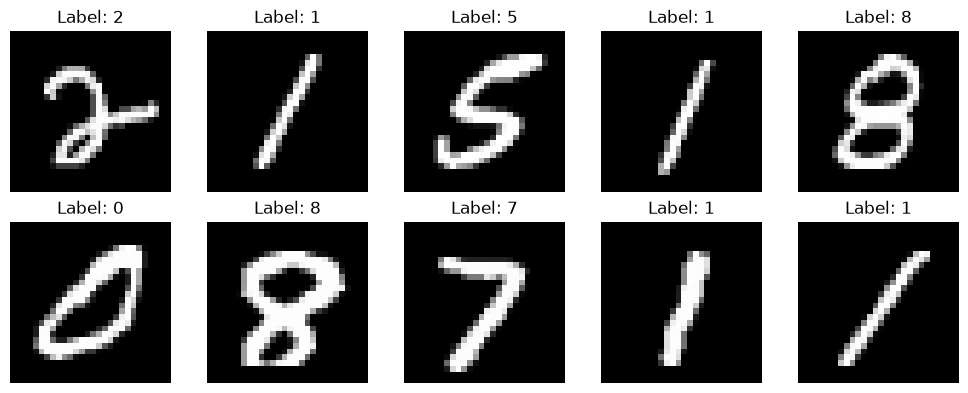

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
(Xm_full, ym_full), (Xm_test, ym_test) = mnist.load_data()
Xm_full = Xm_full.astype('float32') / 255.0
Xm_test = Xm_test.astype('float32') / 255.0
Xm_train, Xm_val, ym_train, ym_val = train_test_split(
    Xm_full, ym_full, test_size=0.1, random_state=SEED, stratify=ym_full)
ym_train_oh = to_categorical(ym_train, 10)
ym_val_oh = to_categorical(ym_val, 10)
ym_test_oh = to_categorical(ym_test, 10)
print('Latih:', Xm_train.shape, '| Validasi:', Xm_val.shape, '| Uji:', Xm_test.shape)
print('Rentang piksel:', Xm_train.min(), '-', Xm_train.max())
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(Xm_train[i], cmap='gray')
    ax.set_title(f'Label: {ym_train[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()
baseline = build_classifier((28, 28), (128, 64), 'relu', 10, flatten=True)
baseline.summary()

In [7]:
EPOCHS = 10
BATCH_SIZE = 128
mnist_rows, mnist_histories, mnist_predictions = [], {}, {}
best_val_accuracy = -np.inf
best_name, best_probability = None, None
for hidden in [(128, 64), (256, 128), (256, 128, 64)]:
    for activation in ['relu', 'sigmoid']:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = build_classifier((28, 28), hidden, activation, 10, flatten=True)
        name = f'{hidden} / {activation}'
        print('Melatih:', name)
        start = time.perf_counter()
        history = model.fit(Xm_train, ym_train_oh, validation_data=(Xm_val, ym_val_oh),
                            epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)
        duration = time.perf_counter() - start
        loss, acc = model.evaluate(Xm_test, ym_test_oh, verbose=0)
        probability = model.predict(Xm_test, batch_size=256, verbose=0)
        final_val_acc = history.history['val_accuracy'][-1]
        mnist_histories[name] = history.history
        mnist_predictions[name] = probability.argmax(axis=1)
        mnist_rows.append({'konfigurasi': name, 'hidden layer': len(hidden),
            'parameter': model.count_params(), 'loss latih': history.history['loss'][-1],
            'akurasi latih': history.history['accuracy'][-1], 'akurasi validasi': final_val_acc,
            'loss uji': loss, 'akurasi uji': acc, 'waktu latih (detik)': duration})
        # Pilih konfigurasi dengan validasi, bukan berdasarkan akurasi uji.
        if final_val_acc > best_val_accuracy:
            best_val_accuracy = final_val_acc
            best_name, best_probability = name, probability.copy()
mnist_results = pd.DataFrame(mnist_rows)
display(mnist_results)
print('Konfigurasi terpilih berdasarkan akurasi validasi akhir:', best_name)

Melatih: (128, 64) / relu


Epoch 1/10


422/422 - 7s - 16ms/step - accuracy: 0.9031 - loss: 0.3451 - val_accuracy: 0.9465 - val_loss: 0.1909


Epoch 2/10


422/422 - 7s - 17ms/step - accuracy: 0.9565 - loss: 0.1463 - val_accuracy: 0.9585 - val_loss: 0.1468


Epoch 3/10


... (114 outputs left out)

Epoch 10/10


422/422 - 10s - 24ms/step - accuracy: 0.9905 - loss: 0.0374 - val_accuracy: 0.9723 - val_loss: 0.0905


,konfigurasi,hidden layer,parameter,loss latih,akurasi latih,akurasi validasi,loss uji,akurasi uji,waktu latih (detik)
0,"(128, 64) / relu",2,109386,0.020059,0.994815,0.973333,0.090333,0.9748,48.199381
1,"(128, 64) / sigmoid",2,109386,0.066312,0.981944,0.968500,0.092100,0.9714,55.333830
2,"(256, 128) / relu",2,235146,0.013977,0.995611,0.976000,0.084256,0.9798,75.798259
3,"(256, 128) / sigmoid",2,235146,0.045872,0.987463,0.972667,0.078998,0.9755,58.064052
4,"(256, 128, 64) / relu",3,242762,0.016853,0.994222,0.973667,0.090823,0.9764,65.057146
5,"(256, 128, 64) / sigmoid",3,242762,0.037399,0.990537,0.972333,0.082618,0.9748,98.964667


Konfigurasi terpilih berdasarkan akurasi validasi akhir: (256, 128) / relu


### Perbandingan akurasi dan waktu pelatihan
Grafik kurva validasi membantu melihat proses belajar; tabel membandingkan hasil akhir setelah jumlah epoch yang sama. Durasi dapat dipengaruhi CPU/GPU, tracing TensorFlow, serta proses lain di komputer.

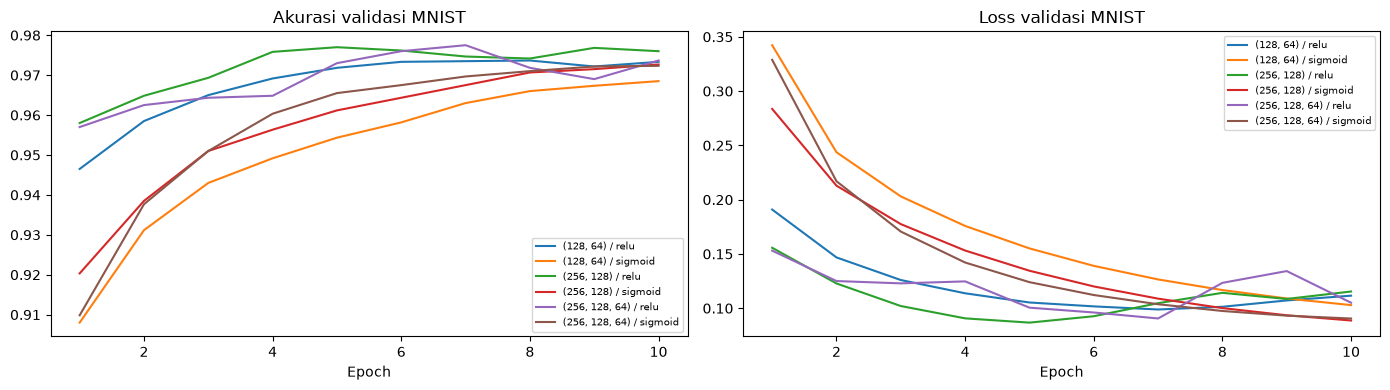

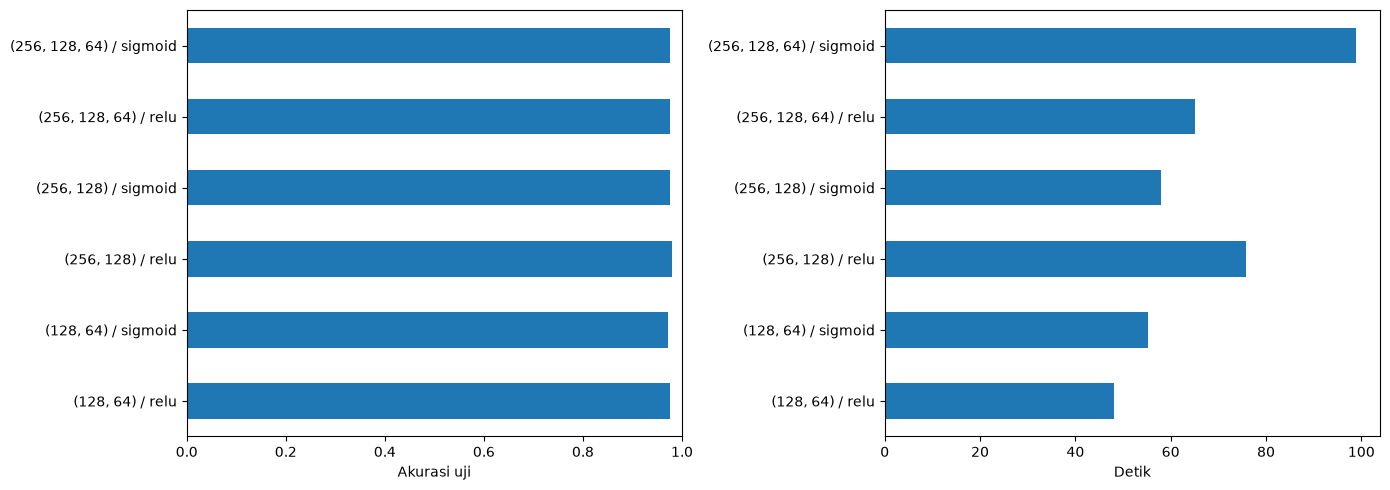

(256, 128) / relu dibanding (128, 64) / relu: selisih akurasi uji +0.50 poin persentase; selisih waktu +27.60 detik.
(256, 128, 64) / relu dibanding (128, 64) / relu: selisih akurasi uji +0.16 poin persentase; selisih waktu +16.86 detik.
(256, 128) / sigmoid dibanding (128, 64) / sigmoid: selisih akurasi uji +0.41 poin persentase; selisih waktu +2.73 detik.
(256, 128, 64) / sigmoid dibanding (128, 64) / sigmoid: selisih akurasi uji +0.34 poin persentase; selisih waktu +43.63 detik.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, history in mnist_histories.items():
    axes[0].plot(range(1, EPOCHS+1), history['val_accuracy'], label=name)
    axes[1].plot(range(1, EPOCHS+1), history['val_loss'], label=name)
for ax, title in zip(axes, ['Akurasi validasi MNIST', 'Loss validasi MNIST']):
    ax.set(xlabel='Epoch', title=title)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mnist_results.plot.barh(x='konfigurasi', y='akurasi uji', ax=axes[0], legend=False)
mnist_results.plot.barh(x='konfigurasi', y='waktu latih (detik)', ax=axes[1], legend=False)
axes[0].set(xlabel='Akurasi uji', ylabel='', xlim=(0, 1))
axes[1].set(xlabel='Detik', ylabel='')
plt.tight_layout()
plt.show()
for activation in ['relu', 'sigmoid']:
    rows = mnist_results[mnist_results['konfigurasi'].str.endswith(activation)]
    initial = rows.iloc[0]
    for _, row in rows.iloc[1:].iterrows():
        print(f"{row['konfigurasi']} dibanding {initial['konfigurasi']}: "
              f"selisih akurasi uji {(row['akurasi uji']-initial['akurasi uji'])*100:+.2f} poin persentase; "
              f"selisih waktu {row['waktu latih (detik)']-initial['waktu latih (detik)']:+.2f} detik.")

### Evaluasi classifier
Untuk konfigurasi terpilih, hitung confusion matrix, precision, recall, F1-score, accuracy, Cohen kappa, dan ROC-AUC dengan pendekatan one-vs-rest untuk setiap angka. Probabilitas softmax digunakan sebagai skor ROC, bukan label hasil argmax.

Pada confusion matrix, baris menunjukkan kelas aktual dan kolom kelas prediksi. Untuk setiap kelas, $precision=TP/(TP+FP)$, $recall=TP/(TP+FN)$, dan $F1=2PR/(P+R)$. Akurasi multikelas adalah jumlah elemen diagonal dibagi jumlah seluruh sampel.

Model: (256, 128) / relu
Akurasi uji: 0.9798
Cohen kappa: 0.9775
              precision    recall  f1-score   support

           0     0.9848    0.9898    0.9873       980
           1     0.9938    0.9903    0.9921      1135
           2     0.9714    0.9874    0.9793      1032
           3     0.9706    0.9812    0.9759      1010
           4     0.9897    0.9766    0.9831       982
           5     0.9907    0.9552    0.9726       892
           6     0.9873    0.9729    0.9800       958
           7     0.9760    0.9874    0.9816      1028
           8     0.9560    0.9825    0.9691       974
           9     0.9790    0.9703    0.9746      1009

    accuracy                         0.9798     10000
   macro avg     0.9799    0.9793    0.9796     10000
weighted avg     0.9800    0.9798    0.9798     10000



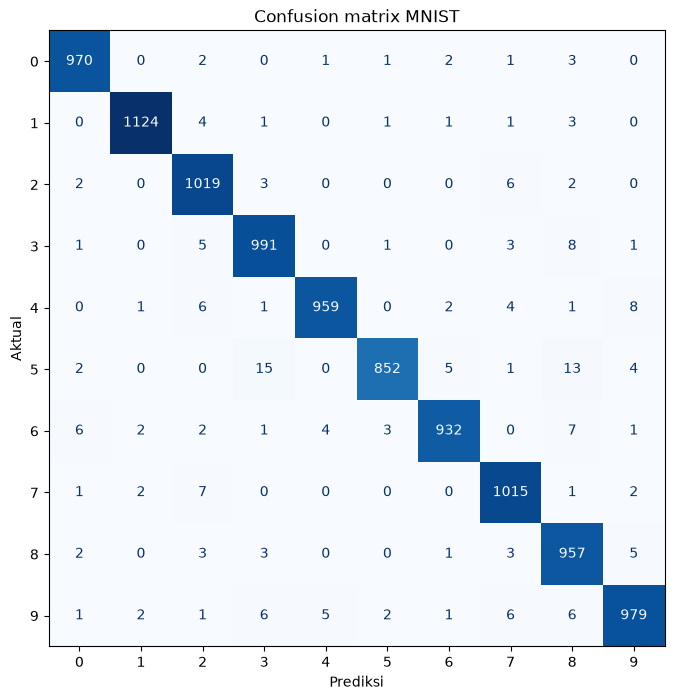

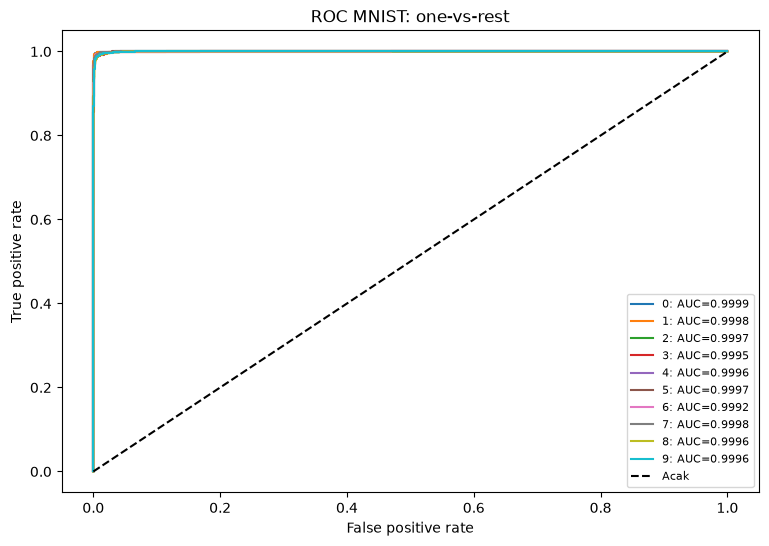

,angka,AUC one-vs-rest
0,0,0.999902
1,1,0.999809
2,2,0.999695
3,3,0.999507
4,4,0.999613
5,5,0.999678
6,6,0.999243
7,7,0.999792
8,8,0.999573
9,9,0.999587


Macro AUC: 0.9996398476327464


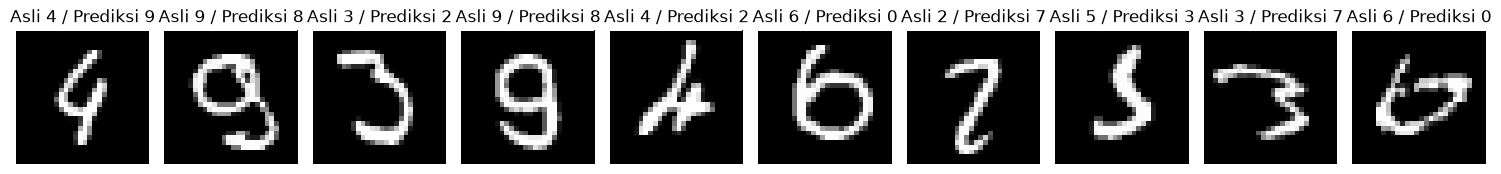

In [9]:
best_pred = best_probability.argmax(axis=1)
cm = confusion_matrix(ym_test, best_pred, labels=np.arange(10))
print('Model:', best_name)
print(f'Akurasi uji: {accuracy_score(ym_test, best_pred):.4f}')
print(f'Cohen kappa: {cohen_kappa_score(ym_test, best_pred):.4f}')
print(classification_report(ym_test, best_pred, labels=np.arange(10), digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set(title='Confusion matrix MNIST', xlabel='Prediksi', ylabel='Aktual')
plt.show()
fig, ax = plt.subplots(figsize=(9, 6))
auc_rows = []
for digit in range(10):
    fpr, tpr, _ = roc_curve(ym_test_oh[:, digit], best_probability[:, digit])
    score = auc(fpr, tpr)
    auc_rows.append({'angka': digit, 'AUC one-vs-rest': score})
    ax.plot(fpr, tpr, label=f'{digit}: AUC={score:.4f}')
ax.plot([0, 1], [0, 1], 'k--', label='Acak')
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='ROC MNIST: one-vs-rest')
ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame(auc_rows))
print('Macro AUC:', pd.DataFrame(auc_rows)['AUC one-vs-rest'].mean())
wrong = np.flatnonzero(best_pred != ym_test)[:10]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(15, 2.5), squeeze=False)
    for ax, idx in zip(axes.ravel(), wrong):
        ax.imshow(Xm_test[idx], cmap='gray')
        ax.set_title(f'Asli {ym_test[idx]} / Prediksi {best_pred[idx]}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### Kesimpulan berdasarkan hasil eksekusi
Sel berikut menghasilkan ringkasan dari hasil aktual. Penambahan neuron dan layer meningkatkan kapasitas serta jumlah parameter, tetapi manfaatnya perlu dibaca bersama hasil validasi, loss, dan waktu pelatihan. Satu kali pelatihan per konfigurasi belum mengukur variasi antar-seed; waktu dan nilai akhir dapat berbeda antarperangkat. Hasil uji semua konfigurasi disajikan untuk menjawab tugas perbandingan, sedangkan pemilihan konfigurasi tetap berdasarkan validasi.

In [10]:
chosen = mnist_results.set_index('konfigurasi').loc[best_name]
fastest = mnist_results.loc[mnist_results['waktu latih (detik)'].idxmin()]
print(f"Konfigurasi terpilih: {best_name}.")
print(f"Akurasi validasi: {chosen['akurasi validasi']:.4f}; "
      f"akurasi uji: {chosen['akurasi uji']:.4f}; loss uji: {chosen['loss uji']:.4f}.")
print(f"Waktu pelatihan konfigurasi terpilih: {chosen['waktu latih (detik)']:.2f} detik.")
print(f"Konfigurasi tercepat: {fastest['konfigurasi']} "
      f"({fastest['waktu latih (detik)']:.2f} detik).")
print(f"Selisih akurasi latih-validasi konfigurasi terpilih: "
      f"{chosen['akurasi latih']-chosen['akurasi validasi']:+.4f}.")
print('Periksa confusion matrix untuk pasangan angka yang paling sering tertukar, '
      'dan classification report untuk precision/recall setiap angka.')

Konfigurasi terpilih: (256, 128) / relu.
Akurasi validasi: 0.9760; akurasi uji: 0.9798; loss uji: 0.0843.
Waktu pelatihan konfigurasi terpilih: 75.80 detik.
Konfigurasi tercepat: (128, 64) / relu (48.20 detik).
Selisih akurasi latih-validasi konfigurasi terpilih: +0.0196.
Periksa confusion matrix untuk pasangan angka yang paling sering tertukar, dan classification report untuk precision/recall setiap angka.
